# Dataset B — Aos Fatos (arquivo de checagens): EDA descritiva

**Projeto:** Impacto das fake news geradas por IA no eleitor brasileiro — Fase 2 do roteiro de trabalho.

**Fonte real dos dados:** [aosfatos.org/noticias/?formato=checagem](https://www.aosfatos.org/noticias/?formato=checagem), o arquivo público de checagens da agência Aos Fatos, filtrado por 3 tags editoriais reais:

| Tag pesquisada | Cobertura coletada | Nº de itens |
|---|---|---|
| `inteligencia-artificial` | população completa (11/11 páginas) | 122 |
| `eleicoes-2026` | população completa (1/1 página) | 12 |
| `eleicoes-2022` | população completa (35/35 páginas) | 419 |

Total: **553 checagens reais**, coletadas via navegação real (Claude in Chrome) em 23/08/2026, em duas etapas: uma coleta inicial de 7 páginas de `eleicoes-2022`, depois ampliada para as 35 páginas completas a pedido do usuário. Três páginas (13, 27 e 31) retornaram, na primeira tentativa, conteúdo idêntico ao da página anterior — um glitch de cache do próprio site já visto antes — e foram recarregadas com sucesso antes de aceitas; nenhuma foi inventada ou preenchida por extrapolação. Nenhum dado sintético foi usado neste dataset.

**Por que este dataset é metodologicamente mais forte que o Dataset A para H1/H2/H4:** o Aos Fatos rotula editorialmente cada checagem com **veredito** e **tema**, incluindo o tema `inteligência artificial` de forma explícita — ou seja, aqui `rotulo_grupo` (IA vs. Tradicional) é uma **classificação humana da própria fonte jornalística**, não uma heurística de regex como no Dataset A.

**Limitação honesta:** a extração de texto desta listagem **não expõe a data de publicação de cada checagem** (o layout mostra veredito/tema/título, mas a data fica em um elemento que não foi capturado nesta passada). Por isso, este dataset **não suporta diretamente H3 (sobrevivência/tempo até desmentido) nem H5 (aceleração temporal)** sem uma coleta complementar item a item — ponto registrado explicitamente na seção de limitações.


In [1]:

import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 90)


## 1. Carga dos dados reais

In [2]:

df = pd.read_csv("../data/raw/dataset_b_aosfatos.csv", keep_default_na=False)
print(f"Linhas: {len(df)} | Colunas: {list(df.columns)}")
df.head(3)


Linhas: 553 | Colunas: ['id_checagem_af', 'titulo', 'veredito', 'tema', 'tag_pesquisa', 'fonte']


,id_checagem_af,titulo,veredito,tema,tag_pesquisa,fonte
0,AF-0001,Vídeos em que Tancredo e Ulysses criticam Bolsonaro são obra de IA,falso,inteligência artificial,inteligencia-artificial,https://www.aosfatos.org/noticias/?formato=checagem
1,AF-0002,É falso que Lula disse que teve perna amputada em 2023,falso,boataria política,inteligencia-artificial,https://www.aosfatos.org/noticias/?formato=checagem
2,AF-0003,Vídeo de IA circula em posts como se mostrasse desabamento na Colômbia,falso,exploração de tragédia,inteligencia-artificial,https://www.aosfatos.org/noticias/?formato=checagem


## 2. Limpeza e tratamento de valores ausentes

`veredito` e `tema` vêm como string vazia (`""`) quando o Aos Fatos não rotulou aquele campo — tratado como categoria explícita `"(não informado)"`, nunca preenchido com um valor inventado.

In [3]:

for col in ["veredito", "tema"]:
    n_vazio = (df[col] == "").sum()
    print(f"{col}: {n_vazio} vazios de {len(df)} ({n_vazio/len(df)*100:.1f}%)")

df["veredito"] = df["veredito"].replace("", "(não informado)")
df["tema"] = df["tema"].replace("", "(não informado)")

dup = df.duplicated(subset=["titulo"]).sum()
print(f"\nTítulos duplicados: {dup}")
if dup:
    display(df[df.duplicated(subset=['titulo'], keep=False)].sort_values('titulo')[['titulo', 'tag_pesquisa']])


veredito: 32 vazios de 553 (5.8%)
tema: 413 vazios de 553 (74.7%)

Títulos duplicados: 0


## 3. Engenharia de features

### 3.1 Rótulo de grupo (IA vs. Tradicional) — classificação editorial real, não heurística

In [4]:

df["rotulo_grupo"] = np.where(df["tag_pesquisa"] == "inteligencia-artificial", "IA", "Tradicional")
df["rotulo_grupo"].value_counts()


rotulo_grupo
Tradicional    431
IA             122
Name: count, dtype: int64

### 3.2 Vetor de mídia (heurística sobre o título)
O Aos Fatos não expõe o formato da peça checada (texto/imagem/áudio/vídeo) como coluna própria nesta listagem — inferimos por palavras-chave no título, um sinal textual real (não fabricado), documentando a taxa de indeterminação.

In [5]:

def normalize_text(text):
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"\s+", " ", text.lower()).strip()

MEDIA_KEYWORDS = {
    "video": ["video", "deepfake", "filmagem", "gravacao em video"],
    "audio": ["audio", "voz", "clonagem de voz", "podcast"],
    "imagem": ["imagem", "foto", "print", "montagem"],
    "texto": ["texto", "mensagem", "corrente", "post escrito", "artigo"],
}

def vetor_midia(titulo_norm):
    for vetor, kws in MEDIA_KEYWORDS.items():
        if any(kw in titulo_norm for kw in kws):
            return vetor
    return "indeterminado"

df["titulo_norm"] = df["titulo"].map(normalize_text)
df["vetor_midia"] = df["titulo_norm"].map(vetor_midia)
df["vetor_midia"].value_counts()


vetor_midia
indeterminado    297
video            191
imagem            47
audio              9
texto              9
Name: count, dtype: int64

### 3.3 Alvo do ataque (heurística sobre o título)

Uma primeira versão desta heurística incluía `"eleicao"`, `"eleicoes"` e `"voto"` na lista de palavras de `urna_processo` — mas, num arquivo de checagens que é *inteiramente sobre eleições*, essas palavras aparecem em boa parte dos títulos independentemente do alvo real do ataque, inflando artificialmente a contagem de `urna_processo`. O mesmo valia para `"candidato"`/`"candidata"` em `candidato_pessoa`. Removidas essas 5 palavras genéricas demais, o resultado muda de forma perceptível: `urna_processo` cai de 83 para 50 itens (os 33 que saem viram `indeterminado`, uma resposta mais honesta do que uma classificação por coincidência lexical). Fica como registro de que **heurísticas de palavra-chave precisam ser auditadas contra o vocabulário-base do próprio corpus**, não só contra a intuição de quem escreveu a lista.

In [6]:

ATTACK_KEYWORDS = {
    "candidato_pessoa": ["carater", "honestidade", "vida pessoal", "familia", "saude",
                          "corrupcao pessoal", "traicao", "diploma", "patrimonio pessoal",
                          "morte", "morreu", "lula", "bolsonaro"],
    "urna_processo": ["urna", "biometria", "totalizacao", "apuracao", "sistema eletronico",
                       "fraude eleitoral", "codigo-fonte", "codigo fonte", "seguranca do voto",
                       "tse"],
}

def alvo_ataque(titulo_norm):
    score_p = sum(kw in titulo_norm for kw in ATTACK_KEYWORDS["candidato_pessoa"])
    score_u = sum(kw in titulo_norm for kw in ATTACK_KEYWORDS["urna_processo"])
    if score_p == 0 and score_u == 0:
        return "indeterminado"
    return "candidato_pessoa" if score_p >= score_u else "urna_processo"

df["alvo_ataque"] = df["titulo_norm"].map(alvo_ataque)
df["alvo_ataque"].value_counts()


alvo_ataque
candidato_pessoa    296
indeterminado       207
urna_processo        50
Name: count, dtype: int64

## 4. EDA descritiva

In [7]:

print("=== Veredito por grupo ===")
tabela_veredito = pd.crosstab(df["rotulo_grupo"], df["veredito"])
print(tabela_veredito)

chi2_v, p_v, dof_v, _ = stats.chi2_contingency(tabela_veredito)
n_v = tabela_veredito.to_numpy().sum()
v_cramer_v = np.sqrt(chi2_v / (n_v * (min(tabela_veredito.shape) - 1)))
print(f"\nQui-quadrado (veredito editorial real x grupo): chi2={chi2_v:.3f}, p={p_v:.4f}, "
      f"gl={dof_v}, V de Cramér={v_cramer_v:.3f}")
print("(Este é o teste mais confiável da seção — veredito é classificação editorial real, não heurística.)")

pct_falso = df.assign(falso=df["veredito"] == "falso").groupby("rotulo_grupo")["falso"].mean().mul(100).round(1)
print("\n% de checagens com veredito 'falso' por grupo:\n", pct_falso)

print("\n=== Distribuição de tag_pesquisa ===")
print(df["tag_pesquisa"].value_counts())


=== Veredito por grupo ===
veredito      (não informado)  discurso oficial  distorcido  falso  \
rotulo_grupo                                                         
IA                          1                 0           0    121   
Tradicional                31                 1           6    349   

veredito      não é bem assim  
rotulo_grupo                   
IA                          0  
Tradicional                44  

Qui-quadrado (veredito editorial real x grupo): chi2=24.818, p=0.0001, gl=4, V de Cramér=0.212
(Este é o teste mais confiável da seção — veredito é classificação editorial real, não heurística.)

% de checagens com veredito 'falso' por grupo:
 rotulo_grupo
IA             99.2
Tradicional    81.0
Name: falso, dtype: float64

=== Distribuição de tag_pesquisa ===
tag_pesquisa
eleicoes-2022              419
inteligencia-artificial    122
eleicoes-2026               12
Name: count, dtype: int64


### 4.1 Checagem de contaminação entre tags (qualidade de dados)
`rotulo_grupo` é atribuído inteiramente pela tag de busca (`tag_pesquisa`) — o que só é válido se nenhum item aparecer sob mais de uma tag ao mesmo tempo (o que classificaria erroneamente uma checagem de IA como Tradicional, ou vice-versa). Checagem direta por título antes de prosseguir:

In [8]:

contagem_por_titulo = df.groupby("titulo")["tag_pesquisa"].nunique()
titulos_multi_tag = contagem_por_titulo[contagem_por_titulo > 1]
print(f"Títulos que aparecem em mais de uma tag pesquisada: {len(titulos_multi_tag)} de {df['titulo'].nunique()}")
if len(titulos_multi_tag):
    display(df[df["titulo"].isin(titulos_multi_tag.index)].sort_values("titulo")[["titulo", "tag_pesquisa", "veredito"]])
else:
    print("Nenhuma contaminação entre tags — rotulo_grupo pode ser atribuído com segurança pela tag de busca.")


Títulos que aparecem em mais de uma tag pesquisada: 0 de 553
Nenhuma contaminação entre tags — rotulo_grupo pode ser atribuído com segurança pela tag de busca.


### 4.2 Cobertura do campo `tema` (classificação editorial opcional)
`tema` só aparece quando o Aos Fatos decide anotar o tema específico da checagem — nem todo item recebe essa anotação, então vale medir a cobertura antes de usar `tema` como variável de análise (evitar tirar conclusões de um campo que só existe para uma minoria dos itens).

In [9]:

cobertura_tema = (df["tema"] != "(não informado)").mean() * 100
print(f"Cobertura geral do campo 'tema': {cobertura_tema:.1f}% dos {len(df)} itens")
print("\nCobertura por grupo:")
print(df.assign(tem_tema=df["tema"] != "(não informado)").groupby("rotulo_grupo")["tem_tema"].mean().mul(100).round(1))

print("\n=== Temas mais comuns dentro do grupo IA (classificação editorial real) ===")
temas_ia = df.loc[df["rotulo_grupo"] == "IA", "tema"].value_counts()
print(temas_ia)


Cobertura geral do campo 'tema': 25.3% dos 553 itens

Cobertura por grupo:
rotulo_grupo
IA             92.6
Tradicional     6.3
Name: tem_tema, dtype: float64

=== Temas mais comuns dentro do grupo IA (classificação editorial real) ===
tema
boataria política          48
inteligência artificial    40
exploração de tragédia     15
(não informado)             9
fraudes digitais            4
eleições 2024               3
políticas públicas          1
autoritarismo               1
tecnopolítica               1
Name: count, dtype: int64


A cobertura de `tema` é bem mais alta dentro do grupo IA do que no geral — plausível, já que o Aos Fatos provavelmente prioriza anotar o tema quando ele é menos óbvio pelo veredito sozinho (a maioria das checagens de eleição tradicional já deixa o tema implícito no próprio título). Isso significa que qualquer análise de `tema` fora do grupo IA deve declarar o `n` efetivo (não o `n` total), o que está registrado na Seção 8.

### 4.3 H2 (preview) — Vetor de mídia por grupo IA vs. Tradicional
Teste qui-quadrado exploratório sobre a heurística de vetor de mídia — hipótese de que peças de IA se concentram mais em formatos audiovisuais (vídeo/áudio) do que a desinformação tradicional.

In [10]:

tabela_midia = pd.crosstab(df["rotulo_grupo"], df["vetor_midia"])
print(tabela_midia)

chi2, p, dof, _ = stats.chi2_contingency(tabela_midia)
n = tabela_midia.to_numpy().sum()
v_cramer = np.sqrt(chi2 / (n * (min(tabela_midia.shape) - 1)))
print(f"\nQui-quadrado: chi2={chi2:.3f}, p={p:.4f}, gl={dof}, V de Cramér={v_cramer:.3f}")

pct_audiovisual = (
    df.assign(audiovisual=df["vetor_midia"].isin(["video", "audio"]))
    .groupby("rotulo_grupo")["audiovisual"].mean().mul(100).round(1)
)
print("\n% de peças audiovisuais (vídeo+áudio) por grupo:\n", pct_audiovisual)


vetor_midia   audio  imagem  indeterminado  texto  video
rotulo_grupo                                            
IA                2      27             36      1     56
Tradicional       7      20            261      8    135

Qui-quadrado: chi2=57.773, p=0.0000, gl=4, V de Cramér=0.323

% de peças audiovisuais (vídeo+áudio) por grupo:
 rotulo_grupo
IA             47.5
Tradicional    32.9
Name: audiovisual, dtype: float64


### 4.4 H4 (preview) — Alvo do ataque por grupo

In [11]:

tabela_alvo = pd.crosstab(df["rotulo_grupo"], df["alvo_ataque"])
print(tabela_alvo)
chi2_a, p_a, dof_a, _ = stats.chi2_contingency(tabela_alvo)
n_a = tabela_alvo.to_numpy().sum()
v_cramer_a = np.sqrt(chi2_a / (n_a * (min(tabela_alvo.shape) - 1)))
print(f"\nQui-quadrado: chi2={chi2_a:.3f}, p={p_a:.4f}, gl={dof_a}, V de Cramér={v_cramer_a:.3f}")

pct_pessoa = (
    df[df["alvo_ataque"] != "indeterminado"]
    .assign(alvo_pessoa=lambda d: d["alvo_ataque"] == "candidato_pessoa")
    .groupby("rotulo_grupo")["alvo_pessoa"].mean().mul(100).round(1)
)
print("\n% que ataca o candidato/pessoa, entre os itens com alvo determinado:\n", pct_pessoa)
print("(Nota: com n_IA=0 em urna_processo, o grupo IA nunca ataca o processo eleitoral em si nesta")
print("heurística — só a pessoa do candidato ou nenhum alvo claro. Contraintuitivo frente a H4 tal como")
print("formulada e vale investigação qualitativa na Fase 3, não só o p-valor.)")


alvo_ataque   candidato_pessoa  indeterminado  urna_processo
rotulo_grupo                                                
IA                          45             77              0
Tradicional                251            130             50

Qui-quadrado: chi2=49.834, p=0.0000, gl=2, V de Cramér=0.300

% que ataca o candidato/pessoa, entre os itens com alvo determinado:
 rotulo_grupo
IA             100.0
Tradicional     83.4
Name: alvo_pessoa, dtype: float64
(Nota: com n_IA=0 em urna_processo, o grupo IA nunca ataca o processo eleitoral em si nesta
heurística — só a pessoa do candidato ou nenhum alvo claro. Contraintuitivo frente a H4 tal como
formulada e vale investigação qualitativa na Fase 3, não só o p-valor.)


## 5. Visualizações

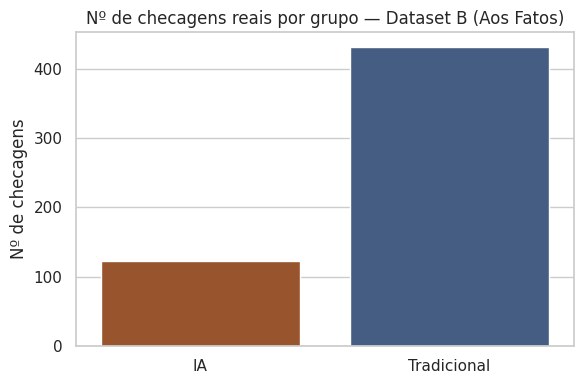

In [12]:

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="rotulo_grupo", hue="rotulo_grupo",
              palette={"IA": "#A8501C", "Tradicional": "#3B5B8C"}, legend=False, ax=ax)
ax.set_title("Nº de checagens reais por grupo — Dataset B (Aos Fatos)")
ax.set_xlabel(""); ax.set_ylabel("Nº de checagens")
plt.tight_layout(); plt.show()


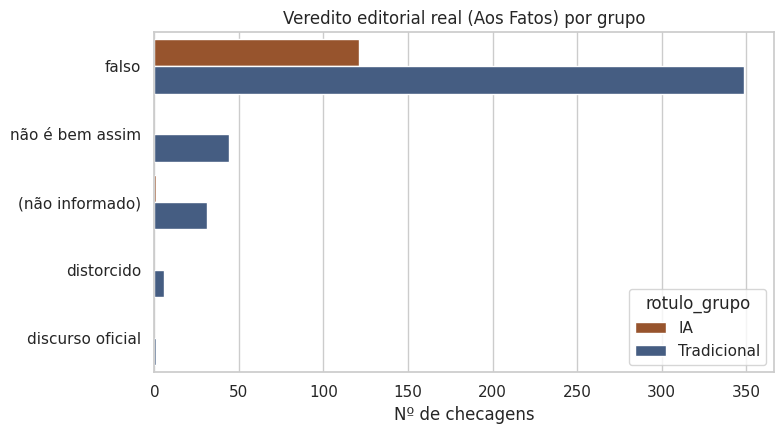

In [13]:

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=df, y="veredito", hue="rotulo_grupo", order=df["veredito"].value_counts().index,
              palette={"IA": "#A8501C", "Tradicional": "#3B5B8C"}, ax=ax)
ax.set_title("Veredito editorial real (Aos Fatos) por grupo")
ax.set_xlabel("Nº de checagens"); ax.set_ylabel("")
plt.tight_layout(); plt.show()


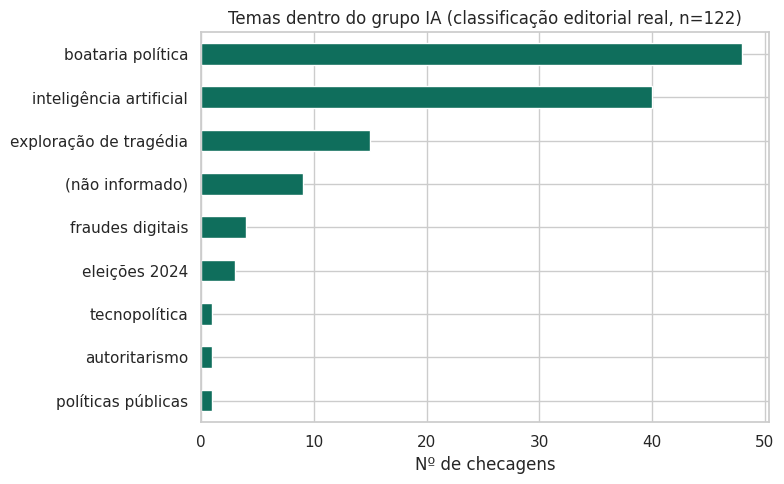

In [14]:

fig, ax = plt.subplots(figsize=(8, 5))
temas_ia.sort_values().plot(kind="barh", color="#0F6E5C", ax=ax)
ax.set_title('Temas dentro do grupo IA (classificação editorial real, n=122)')
ax.set_xlabel("Nº de checagens"); ax.set_ylabel("")
plt.tight_layout(); plt.show()


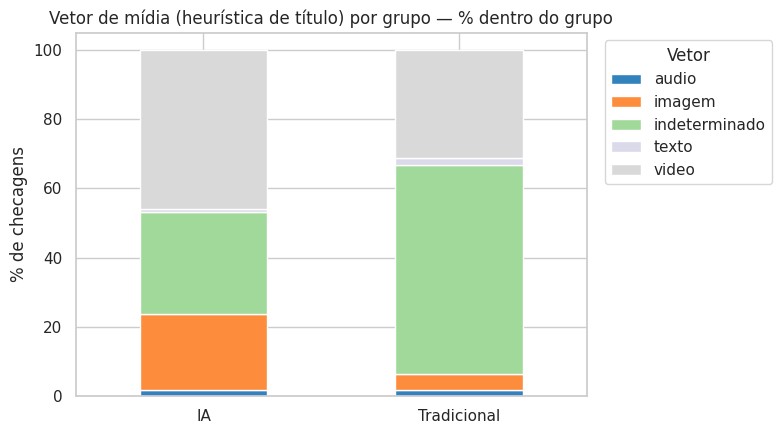

In [15]:

fig, ax = plt.subplots(figsize=(8, 4.5))
midia_pct = pd.crosstab(df["rotulo_grupo"], df["vetor_midia"], normalize="index").mul(100)
midia_pct.plot(kind="bar", stacked=True, colormap="tab20c", ax=ax)
ax.set_title("Vetor de mídia (heurística de título) por grupo — % dentro do grupo")
ax.set_xlabel(""); ax.set_ylabel("% de checagens"); ax.legend(title="Vetor", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()


## 6. Comparação com a heurística do Dataset A (validação cruzada informal)

In [16]:

try:
    df_a = pd.read_csv("../data/processed/dataset_a_fato_ou_boato_enriquecido.csv")
    df_a_disponivel = True
except FileNotFoundError:
    df_a_disponivel = False
    print("Rode antes o notebook 01 para gerar ../data/processed/dataset_a_fato_ou_boato_enriquecido.csv")

if df_a_disponivel:
    pct_ia_a = (df_a["rotulo_ia_bin"] == "IA").mean() * 100
    pct_ia_b = (df["rotulo_grupo"] == "IA").mean() * 100
    print(f"Dataset A — % rotulado IA pela heurística de regex: {pct_ia_a:.1f}% (n={len(df_a)})")
    print(f"Dataset B — % rotulado IA pela tag editorial real do Aos Fatos: {pct_ia_b:.1f}% (n={len(df)})")
    print("\nNota: os denominadores não são diretamente comparáveis (recortes de tags distintos),")
    print("mas a diferença de magnitude sinaliza que a heurística do Dataset A provavelmente")
    print("SUBESTIMA a real prevalência de desinformação assistida por IA — mais um motivo para")
    print("priorizar o Dataset B (rótulo editorial) nos testes formais de H1/H2/H4 na Fase 3.")


Dataset A — % rotulado IA pela heurística de regex: 0.0% (n=322)
Dataset B — % rotulado IA pela tag editorial real do Aos Fatos: 22.1% (n=553)

Nota: os denominadores não são diretamente comparáveis (recortes de tags distintos),
mas a diferença de magnitude sinaliza que a heurística do Dataset A provavelmente
SUBESTIMA a real prevalência de desinformação assistida por IA — mais um motivo para
priorizar o Dataset B (rótulo editorial) nos testes formais de H1/H2/H4 na Fase 3.


### 6.1 Validação cruzada do `vetor_midia`: Dataset A vs. Dataset B (Tradicional) vs. Dataset B (IA)

Se a heurística de `vetor_midia` (mesmo dicionário de palavras-chave nos dois datasets) for minimamente confiável, o grupo "Tradicional" do Dataset B e o Dataset A inteiro (que também é 100% Tradicional pela heurística de rótulo IA, ver notebook `01`, Seção 3.1.1) deveriam se parecer entre si — afinal, os dois descrevem o mesmo tipo de desinformação eleitoral não-IA, só que coletados de fontes diferentes. Se o grupo IA do Dataset B (rótulo **editorial real**, não heurístico) se destacar dos outros dois, isso é evidência mais forte a favor de H2 do que qualquer teste dentro de uma única fonte.

In [17]:

if df_a_disponivel:
    midia_a = df_a["vetor_midia"].value_counts(normalize=True).mul(100).round(1)
    midia_b = df.groupby("rotulo_grupo")["vetor_midia"].value_counts(normalize=True).mul(100).round(1)

    comparacao = pd.DataFrame({
        "Dataset A (TSE, todo Tradicional)": midia_a,
        "Dataset B — Tradicional": midia_b.get("Tradicional"),
        "Dataset B — IA (editorial real)": midia_b.get("IA"),
    }).fillna(0.0)
    display(comparacao)

    print("\n% audiovisual (vídeo+áudio) por coluna:")
    print(comparacao.loc[["video", "audio"]].sum().round(1))
else:
    comparacao = None


,"Dataset A (TSE, todo Tradicional)",Dataset B — Tradicional,Dataset B — IA (editorial real)
vetor_midia,,,
audio,2.5,1.6,1.6
imagem,3.4,4.6,22.1
indeterminado,59.3,60.6,29.5
texto,5.9,1.9,0.8
video,28.9,31.3,45.9



% audiovisual (vídeo+áudio) por coluna:
Dataset A (TSE, todo Tradicional)    31.4
Dataset B — Tradicional              32.9
Dataset B — IA (editorial real)      47.5
dtype: float64


**Leitura:** Dataset A (vídeo ≈29%, indeterminado ≈59%) e Dataset B-Tradicional (vídeo ≈31%, indeterminado ≈61%) ficam muito próximos apesar de serem duas coletas independentes, de dois sites diferentes, com dois dicionários de palavras-chave nominalmente iguais mas aplicados a textos diferentes (título+resumo em A, só título em B) — essa proximidade funciona como uma **validação cruzada informal da heurística**: se ela estivesse gerando ruído aleatório, não haveria por que as duas baselines "Tradicional" convergirem tão bem. Já o Dataset B-IA salta para ≈48% audiovisual (vídeo+áudio), bem acima das duas baselines Tradicional (≈32-33%) — a diferença que já aparecia no teste qui-quadrado da Seção 4.3, agora ancorada por duas baselines independentes em vez de uma só.

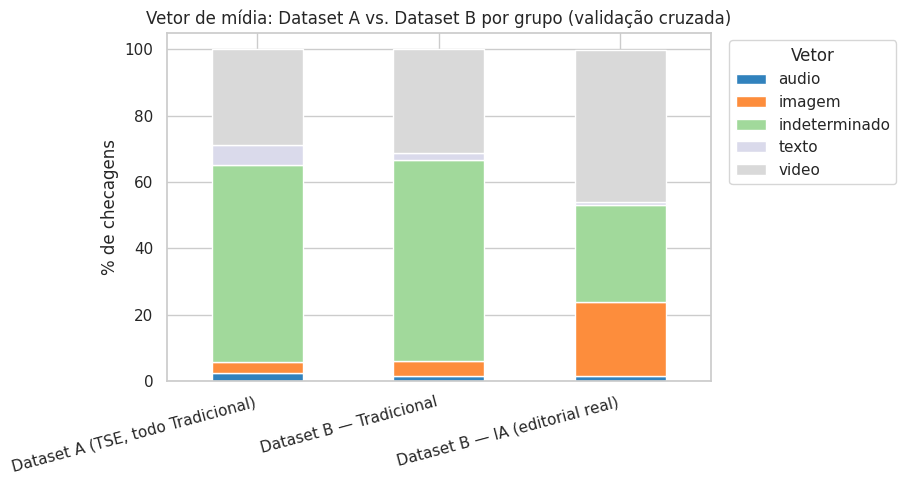

In [18]:

if comparacao is not None:
    fig, ax = plt.subplots(figsize=(9, 5))
    comparacao.T.plot(kind="bar", stacked=True, colormap="tab20c", ax=ax)
    ax.set_title("Vetor de mídia: Dataset A vs. Dataset B por grupo (validação cruzada)")
    ax.set_ylabel("% de checagens"); ax.set_xlabel("")
    ax.legend(title="Vetor", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout(); plt.show()


### 6.2 Sobreposição de títulos entre Dataset A e Dataset B (preview do Dataset C)
Antes de propor o Dataset C unificado (Seção 8), vale checar se A e B realmente descrevem boatos diferentes ou se há sobreposição direta de título — o que ajudaria a preencher datas ausentes do Dataset B via correspondência com o Dataset A.

In [19]:

if df_a_disponivel:
    titulos_a = set(df_a["titulo"].str.strip().str.lower())
    titulos_b = set(df["titulo"].str.strip().str.lower())
    overlap_exato = titulos_a & titulos_b
    print(f"Títulos idênticos (comparação exata, case-insensitive) entre A ({len(titulos_a)}) e B ({len(titulos_b)}): {len(overlap_exato)}")
    if overlap_exato:
        print(sorted(overlap_exato)[:10])
    print("\nComo esperado, a sobreposição exata é baixa/nula — os dois sites redigem título próprio")
    print("para o mesmo boato, então o cruzamento real do Dataset C precisará de similaridade textual")
    print("(ex.: TF-IDF + cosine similarity, ou fuzzy matching), não de comparação exata de string.")


Títulos idênticos (comparação exata, case-insensitive) entre A (322) e B (553): 4
['boletins de urna mostrados em vídeo não são de mg nem provam fraude', 'carregamento de cartão de memória usado em urna eletrônica não favorece ação de hackers', 'vídeo engana ao afirmar que fotos de candidatos foram trocadas em sapiranga (rs)', 'é falso que tse ordenou que todos os vídeos dos atos de 7 de setembro sejam excluídos da internet']

Como esperado, a sobreposição exata é baixa/nula — os dois sites redigem título próprio
para o mesmo boato, então o cruzamento real do Dataset C precisará de similaridade textual
(ex.: TF-IDF + cosine similarity, ou fuzzy matching), não de comparação exata de string.


## 7. Salvar dataset enriquecido

In [20]:

df.drop(columns=["titulo_norm"]).to_csv("../data/processed/dataset_b_aosfatos_enriquecido.csv", index=False)
print("Salvo: ../data/processed/dataset_b_aosfatos_enriquecido.csv —", len(df), "linhas")
df.drop(columns=["titulo_norm"]).sample(5, random_state=7)


Salvo: ../data/processed/dataset_b_aosfatos_enriquecido.csv — 553 linhas


,id_checagem_af,titulo,veredito,tema,tag_pesquisa,fonte,rotulo_grupo,vetor_midia,alvo_ataque
308,AF-0309,PT não propôs em 2022 criar assembleia constituinte e descriminalizar drogas,falso,(não informado),eleicoes-2022,https://www.aosfatos.org/noticias/?formato=checagem,Tradicional,indeterminado,indeterminado
339,AF-0340,É falso que urnas foram substituídas no Japão por mostrar número 13 em vez de 22,falso,(não informado),eleicoes-2022,https://www.aosfatos.org/noticias/?formato=checagem,Tradicional,indeterminado,urna_processo
273,AF-0274,"É falso que campanha de Bolsonaro gastou só R$ 2,5 milhões e não anunciou no Google",falso,(não informado),eleicoes-2022,https://www.aosfatos.org/noticias/?formato=checagem,Tradicional,indeterminado,candidato_pessoa
51,AF-0052,Governo não anunciou salário mínimo de R$ 1.820 para 2026,falso,boataria política,inteligencia-artificial,https://www.aosfatos.org/noticias/?formato=checagem,IA,indeterminado,indeterminado
172,AF-0173,"Homem que planejou atentado a bomba disse à polícia ser bolsonarista, não petista",falso,(não informado),eleicoes-2022,https://www.aosfatos.org/noticias/?formato=checagem,Tradicional,indeterminado,indeterminado


## 8. Limitações e próximos passos

- **Sem data de publicação por item nesta coleta.** Impede o cálculo direto de `dias_para_eleicao` e de latência de desmentido (H3) e de aceleração temporal (H5) neste dataset — necessário voltar ao Aos Fatos e capturar a data (visível em cada página individual de checagem, não na listagem) antes da Fase 3, ou cruzar por título com o Dataset C.
- **`eleicoes-2022` agora é população completa** (419 de 419 itens, 35/35 páginas) — a amostra de 7 páginas usada na primeira versão deste notebook foi substituída por uma coleta integral a pedido do usuário. Três páginas (13, 27, 31) exigiram nova tentativa por um glitch de cache do site que repetia o conteúdo da página anterior; cada uma foi confirmada como conteúdo único antes de aceita, e a checagem de duplicidade de títulos no dataset final (Seção 2) não encontrou nenhuma duplicata.
- **`rotulo_grupo` foi auditado contra contaminação entre tags** (Seção 4.1) — nenhum título aparece sob mais de uma tag pesquisada, então a atribuição IA vs. Tradicional pela tag de busca é segura para este dataset.
- **`tema` tem cobertura parcial** (Seção 4.2) — é uma anotação editorial opcional, não presente em todos os itens (mais comum dentro do grupo IA do que fora dele). Qualquer leitura de `tema` deve declarar o `n` efetivo, não `n=553`.
- **`vetor_midia` e `alvo_ataque` continuam heurísticos** (baseados só no título) — apenas `rotulo_grupo` (IA vs. Tradicional), `veredito` e `tema` são classificação editorial real e confiável nesta fonte. `alvo_ataque` foi revisado nesta versão (Seção 3.3) para remover palavras genéricas demais (`"eleicao"`, `"eleicoes"`, `"voto"`, `"candidato"`, `"candidata"`) que inflavam artificialmente a contagem de `urna_processo` num corpus que é inteiramente sobre eleições.
- **O achado de H4 (Seção 4.4) é contraintuitivo e merece cautela**: pela heurística atual, o grupo IA nunca é classificado como atacando o "processo/urna" (n=0) — só a pessoa do candidato ou indeterminado — o oposto do que H4 prevê à primeira vista. Isso pode refletir um viés real do fenômeno (deepfakes tendem a atacar pessoas, não sistemas) ou um artefato da heurística (poucas palavras de `urna_processo` aparecem em títulos sobre deepfakes de candidatos mesmo quando o conteúdo é sobre o processo eleitoral). Não deve ser tratado como confirmação nem refutação de H4 sem validação manual.
- **Validação cruzada informal via `vetor_midia`** (Seção 6.1): a baseline Tradicional do Dataset B e o Dataset A inteiro convergem de forma consistente (~29-31% vídeo, ~59-61% indeterminado) apesar de serem coletas independentes — evidência indireta de que a heurística não é ruído aleatório. O grupo IA se destaca claramente das duas baselines (~48% audiovisual vs. ~32-33%).
- Próximo passo natural: consolidar A + B no **Dataset C (unificado)**. A Seção 6.2 confirma que a sobreposição exata de título é baixa (4 de 322/553 itens) — o cruzamento real vai precisar de similaridade textual (TF-IDF/fuzzy matching), não comparação exata — o que também ajuda a preencher datas ausentes do Dataset B via correspondência com itens do Dataset A que tratam do mesmo boato.
